# State of the art: duration and EM estimators, macro-conditioned matrices and a reference library

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 02 and 03 of this topic (the estimators and the generators)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the practices the research found for estimating a rating transition matrix: the cohort and the duration estimators, the matrix repairs, EM, Aalen-Johansen, macro-conditioned matrices and a reference library;
- compare six estimators of the one-year PD on data whose truth is known, with the bias and the error of each and its Monte Carlo standard error, and run a small study of your own with the engine's performance harness;
- read what the estimators say on the real S&P matrix, at one and at five years, and how far apart they are;
- say what the product does and does not do on each practice, and which comparison with a reference library is not run.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.transitions import estimators
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files of case C04, from ESMA's CEREP publication (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/): `data/derived/C04/sp.json` (the real S&P matrix, its generators and the speculative-grade default rate by year), `data/derived/C04/models-transitions.json` (the generator fitted to S&P and used as truth) and `data/derived/C04/markov.json` (the committed study: 200 seeded datasets from that generator, six estimators). The next cell loads them and prints the engine version that baked them.

In [2]:
# Load the three artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, models, markov = load("sp.json"), load("models-transitions.json"), load("markov.json")
out = sp["outputs"]
grades = out["grades"]
study = markov["outputs"]["rungs"][0]["estimators"]
truth = np.array(study["cohort"]["truth"])

for label, doc in (("sp", sp), ("models-transitions", models), ("markov", markov)):
    print(f"{label:20s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("true one-year PD of the generator (%):", " ".join(f"{100 * v:.4f}" for v in truth))
print("estimators in the committed study:", list(study))

sp                   baked by riskvalidation 0.4.3 | installed 0.8.1
models-transitions   baked by riskvalidation 0.4.3 | installed 0.8.1
markov               baked by riskvalidation 0.4.3 | installed 0.8.1
true one-year PD of the generator (%): 0.0066 0.0049 0.0288 0.0817 0.3462 1.1731 8.0618
estimators in the committed study: ['cohort', 'duration', 'em', 'diagonal', 'weighted', 'jlt']


## Method

**The comparison.** An estimator is judged on data whose truth is known, over many datasets, never on one sample (Morris, White and Crowther, 2019). For each estimator $\hat\theta$ of a PD $\theta$ over $n$ datasets the harness reports the bias $\bar{\hat\theta} - \theta$, the empirical standard error, the root mean squared error (RMSE) and, for each, its Monte Carlo standard error: how much the number would move with other datasets. The relative RMSE (RMSE over $\theta$) is read as "the typical error is this fraction of the PD". The committed study runs six estimators on 200 datasets, five years of annual snapshots from the generator of notebook 03: the pooled **cohort** matrix, the **duration** generator, the **EM** generator of the snapshots and the three repairs of the pooled matrix (**diagonal**, **weighted**, **JLT**). The next cell prints the relative bias and RMSE of each, with the Monte Carlo standard error of the bias.

In [3]:
# Relative bias and relative RMSE of the six estimators by grade, from the committed 200-dataset study
names = {"cohort": "cohort", "duration": "duration", "em": "EM", "diagonal": "diagonal", "weighted": "weighted", "jlt": "JLT"}
print("datasets:", study["cohort"]["n"][0])
print("relative bias (bias / true PD)")
print(f"{'':10s}" + "".join(f"{g:>9s}" for g in grades))
for key, label in names.items():
    print(f"{label:10s}" + "".join(f"{b / t:9.3f}" for b, t in zip(study[key]["bias"], truth)))
print("relative RMSE (RMSE / true PD)")
for key, label in names.items():
    print(f"{label:10s}" + "".join(f"{r / t:9.3f}" for r, t in zip(study[key]["rmse"], truth)))
print("Monte Carlo standard error of the relative bias, duration estimator:", " ".join(f"{m / t:.3f}" for m, t in zip(study["duration"]["bias_mcse"], truth)))

datasets: 200
relative bias (bias / true PD)
                AAA       AA        A      BBB       BB        B    CCC-C
cohort       -0.438   -0.028   -0.045    0.010   -0.003    0.001    0.014
duration     -0.061    0.036   -0.008    0.004   -0.002    0.003    0.011
EM            0.500    0.267   -0.054    0.009   -0.003    0.001    0.013
diagonal      0.626    0.297   -0.036    0.010   -0.003    0.001    0.013
weighted      0.606    0.296   -0.037    0.010   -0.004   -0.001    0.011
JLT           0.605    0.424    0.125    0.193    0.210    0.253    0.032
relative RMSE (RMSE / true PD)
cohort        5.609    2.184    0.529    0.386    0.227    0.114    0.098
duration      1.245    1.882    0.503    0.351    0.215    0.100    0.085
EM            5.634    2.056    0.509    0.385    0.227    0.114    0.098
diagonal      5.722    2.086    0.516    0.386    0.227    0.114    0.098
weighted      5.636    2.085    0.516    0.386    0.227    0.114    0.098
JLT           5.759    2.237    0.54

A small study of your own, to see how the numbers arise. The next cell draws 60 seeded datasets from the same generator, computes the pooled cohort estimate and the duration estimate on each, and passes the 60 estimates of each grade to the engine's `estimator_performance`, which returns the bias, the RMSE and their Monte Carlo errors. With 60 draws the errors are larger than the committed study's, and they say so.

In [4]:
# Run 60 seeded draws, estimate with the cohort and the duration estimators, and summarise with the performance harness
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
obligors = tuple(models["fit"]["generator"]["obligors"])
generator = RatingPaths(q_true, obligors, horizon=5.0, snapshots=tuple(float(t) for t in range(6)))
draws = 60
cohort_est, duration_est = np.zeros((draws, 7)), np.zeros((draws, 7))
for i, child in enumerate(np.random.SeedSequence(20261021).spawn(draws)):
    data = generator.draw(np.random.default_rng(child))
    cohort_est[i] = estimators.pooled_cohort([s["counts"] for s in data["steps"]])["matrix"][:7, -1]
    duration_est[i] = expm(estimators.duration_generator(data["segments"], 8)["generator"])[:7, -1]

print(f"{'grade':8s}{'estimator':>12s}{'relative bias':>20s}{'relative RMSE':>20s}{'RMSE se':>20s}")
for g in (0, 1, 5, 6):
    for label, est in (("cohort", cohort_est), ("duration", duration_est)):
        perf = estimator_performance(est[:, g], truth[g])
        print(f"{grades[g]:8s}{label:>12s}{perf['bias'] / truth[g]:20.3f}{perf['rmse'] / truth[g]:20.3f}{perf['rmse_mcse'] / truth[g]:20.3f}")

grade      estimator       relative bias       relative RMSE             RMSE se
AAA           cohort              -0.077               7.090               3.475
AAA         duration               0.266               1.402               0.138
AA            cohort              -0.076               2.317               0.421
AA          duration               0.229               2.289               0.458
B             cohort              -0.001               0.116               0.009
B           duration              -0.005               0.103               0.008
CCC-C         cohort              -0.001               0.084               0.006
CCC-C       duration               0.001               0.073               0.007


## State of the art

### What the research found, and what the product does

- **Cohort against duration.** The industry standard estimates the one-year matrix from annual snapshots, the cohort method, removing withdrawals (Anderson and Goodman, 1957; Schuermann and Hanson, 2004). The duration (hazard-rate) estimator of Lando and Skodeberg (2002) uses every jump and the time in each grade and gives non-zero probabilities for rare transitions. *Product:* both are in the engine; the cohort one runs on the real CEREP tables, the duration one only where paths exist, so the product compares them on simulated paths of known truth (above and notebook 02).
- **Repairing the matrix.** The one-year matrix has no exact generator (Israel, Rosenthal and Wei, 2001); the diagonal, weighted and JLT repairs and EM are the practice. *Product:* all four, with the L1 distance and the PD at five years (notebook 03).
- **Aalen-Johansen** for time-inhomogeneous chains. *Product:* in the engine and in notebook 02.
- **Macro-conditioned matrices.** Belkin, Suchower and Forest (1998) condition the matrix on a credit-cycle factor $z$. *Product:* it reads the factor each year implies (`vasicek.implied_factor`, notebook 01) and tests whether the matrix is the same every year (notebook 04); it does not fit a macro-conditioned matrix. The next cell reads the factor of each year from the speculative-grade default rate, which is what such a model would be conditioned on.
- **A reference library.** The research names the `transitionMatrix` package as an independent implementation to cross-check the cohort estimator against. *Product:* the engine's own tests reconcile its cohort estimator with `transitionMatrix` 0.5.1 (RV-415, announced in the release notes of engine 0.8.0): `pooled_cohort` and `cohort` equal the package's cohort estimator element-wise within 1e-12 on a seeded panel with withdrawals. They run where the optional `transitions` extra of the wheel is installed. **This notebook does not rerun them**: `transitionMatrix` is not among its pinned packages, so the equality is reported from the engine and not counted as a result here. What the notebook shows is the agreement of the product's own estimators, read below.

In [5]:
# The credit-cycle factor of each year from the speculative-grade default rate, and the worst and best years
labels = out["mobility"]["labels"]
spec = np.array([np.nan if v is None else v for v in out["mobility"]["spec_default_rate"]])
ttc_spec = float(np.nanmean(spec))
rho = 0.12                                              # the Basel minimum corporate correlation, an assumption
z = vasicek.implied_factor(spec, ttc_spec, rho)
order = np.argsort(z)
print("average speculative-grade default rate:", round(ttc_spec, 4), "| assumed correlation:", rho)
print("worst years (lowest factor):", ", ".join(f"{labels[k]} ({z[k]:.2f})" for k in order[:4]))
print("best years (highest factor):", ", ".join(f"{labels[k]} ({z[k]:.2f})" for k in order[::-1][:4]))
print("years with a negative factor:", int((z < 0).sum()), "of", len(z))

average speculative-grade default rate: 0.0375 | assumed correlation: 0.12
worst years (lowest factor): 2009 (-1.72), 2002 (-1.42), 2001 (-1.35), 2000 (-0.95)
best years (highest factor): 2007 (1.15), 2006 (0.99), 2005 (0.85), 2014 (0.70)
years with a negative factor: 14 of 26


Now the estimators on the real S&P matrix. The artifact commits the one-year and five-year PD each estimator gives (`outputs.generators`) and the cohort projection by the matrix to the fifth power. The cell prints them for AAA, B and CCC-C, and the largest gap between estimators at each grade, which is the agreement of the product's own estimators and not a reconciliation with a reference library.

In [6]:
# One-year and five-year PD of each estimator on the real S&P matrix, and the largest gap between estimators
gen = out["generators"]
pooled = np.array(out["pooled"]["matrix"], dtype=float)
one = {"cohort (matrix)": pooled[:7, -1], **{names[k]: np.array(gen[k]["pd_1y"], dtype=float) for k in ("diagonal", "weighted", "jlt", "em")}}
five = {"cohort (matrix^5)": np.array(gen["cohort_power"]["pd_5y"], dtype=float), **{names[k]: np.array(gen[k]["pd_5y"], dtype=float) for k in ("diagonal", "weighted", "jlt", "em")}}
shown = (0, 5, 6)
print(f"{'':22s}" + "".join(f"{grades[g] + ' 1y':>10s}" for g in shown))
for label, v in one.items():
    print(f"{label:22s}" + "".join(f"{100 * v[g]:10.4f}" for g in shown))
print(f"{'':22s}" + "".join(f"{grades[g] + ' 5y':>10s}" for g in shown))
for label, v in five.items():
    print(f"{label:22s}" + "".join(f"{100 * v[g]:10.4f}" for g in shown))
without_jlt = [v for k, v in five.items() if k != "JLT"]
print("largest gap between the cohort power, diagonal, weighted and EM five-year PDs (points):", {grades[g]: round(float(100 * (max(v[g] for v in without_jlt) - min(v[g] for v in without_jlt))), 4) for g in shown})
print("JLT minus EM, five-year PD (points):", {grades[g]: round(float(100 * (five["JLT"][g] - five["EM"][g])), 4) for g in shown})

                          AAA 1y      B 1y  CCC-C 1y
cohort (matrix)           0.0000    1.1731    8.0675
diagonal                  0.0069    1.1727    8.0543
weighted                  0.0068    1.1709    8.0190
JLT                       0.0073    1.4664    8.2170
EM                        0.0066    1.1731    8.0618
                          AAA 5y      B 5y  CCC-C 5y
cohort (matrix^5)         0.1025    8.2143   25.2981
diagonal                  0.1270    8.1917   25.1454
weighted                  0.1263    8.1758   25.0877
JLT                       0.1379    9.0631   26.1829
EM                        0.1225    8.2142   25.2657
largest gap between the cohort power, diagonal, weighted and EM five-year PDs (points): {'AAA': 0.0245, 'B': 0.0386, 'CCC-C': 0.2104}
JLT minus EM, five-year PD (points): {'AAA': 0.0154, 'B': 0.8488, 'CCC-C': 0.9172}


The figure draws the relative RMSE of the six estimators, by grade, on a logarithmic scale.

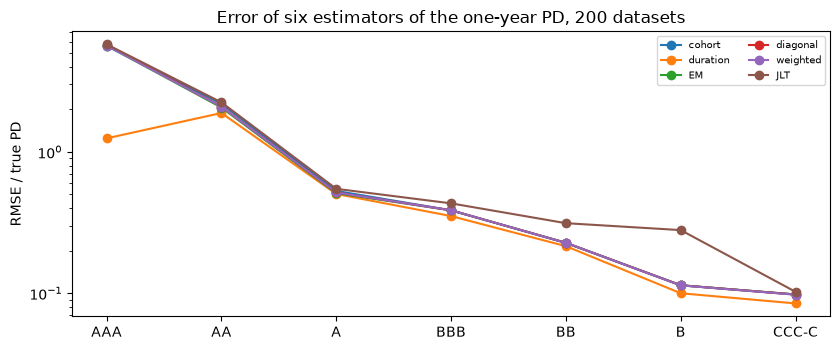

In [7]:
# Draw the relative RMSE of the six estimators by grade
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for key, label in names.items():
    ax.plot(range(7), np.array(study[key]["rmse"]) / truth, marker="o", label=label)
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_ylabel("RMSE / true PD")
ax.set_title("Error of six estimators of the one-year PD, 200 datasets")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## Results

- **Duration against cohort, on a known truth.** Over the 200 committed datasets the duration estimator of AAA has a relative bias of -0.06 (Monte Carlo error 0.09) and a relative RMSE of 1.25; the cohort estimator has a bias of -0.44 and an RMSE of 5.61, and returns exactly zero in 99% of the datasets. From A to CCC-C the two are close (relative RMSE 0.53 against 0.50 at A, 0.098 against 0.085 at CCC-C). The small study with 60 draws gives the same order, with the error the harness reports: for AAA a relative RMSE of 1.40 (standard error 0.14) for duration and 7.09 (3.5) for the cohort estimator.
- **EM and the repairs add nothing at the thin end.** The EM, diagonal and weighted estimators read the same annual snapshots as the cohort estimator and have its error for AAA (relative RMSE 5.63, 5.72 and 5.64) and a positive bias of 0.5 to 0.6 there, because they never return zero. JLT is worse from BBB (relative RMSE 0.43 against 0.39; 0.28 against 0.11 at B) with a bias of 0.19 to 0.25 in the middle grades.
- **Macro conditioning.** The speculative-grade default rate averages 3.75%; with an assumed correlation of 12% the lowest factors are 2009 (-1.72), 2002 (-1.42), 2001 (-1.35) and 2000 (-0.95), the highest 2007 (1.15), 2006 (0.99), 2005 (0.85) and 2014 (0.70), and 14 of the 26 years are negative. The product reads this factor and tests the stability of the matrix; it does not fit a conditioned matrix.
- **On the real matrix the estimators agree where data are plentiful.** Five-year PDs of CCC-C: 25.30% (matrix to the fifth power), 25.15% (diagonal), 25.09% (weighted), 25.27% (EM): a spread of 0.21 points; JLT gives 26.18%, 0.92 points above EM. For B the spread of the first four is 0.04 points and JLT is 0.85 above EM; for AAA the first four lie between 0.103% and 0.127%.
- **The reference library.** The equality of the cohort estimator with `transitionMatrix` is an engine test (RV-415) that this notebook does not rerun and does not count; the agreement above is the product's own estimators against each other.

What this notebook does not show: the effect of the default definition and of withdrawals on these PDs, and the coverage of intervals on thin grades (notebook 10).

## Summary

- The cohort estimator cannot see the AAA PD from annual snapshots, and neither can EM or the matrix repairs; the duration estimator can, where paths exist, with an error of the order of the PD itself.
- Where data are plentiful the estimators agree to a fraction of a point at five years; JLT stays about a point above.
- Estimators are compared by bias and RMSE with their Monte Carlo errors, on known truth; a small study with the harness shows how the numbers arise.
- The product reads the credit-cycle factor and tests the stability of the matrix but fits no conditioned matrix, and runs no reconciliation with a reference library.

**What to try next.** Raise the draws of the small study to 200 and see the standard errors fall; then read notebook 09.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1). https://doi.org/10.1214/aoms/1177707039
- Israel, R. B., Rosenthal, J. S. and Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Lando, D. and Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Belkin, B., Suchower, S. and Forest, L. R. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, third quarter.
- Smith, A. and dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, for the EM generator.
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11), doi 10.1002/sim.8086.